# 1. 量子クラスタリングによる画像異常検知チュートリアル

このノートブックでは、画像データから特徴量を抽出し、量子アニーリングを用いたクラスタリングによって異常検知を行う一連の流れを紹介します。

異常検知では、正常データのみを用いて判定ルールを設計する方法や、教師あり分類として正常・異常を識別する方法がよく用いられます。一方で、本チュートリアルでは、画像を特徴空間に写像したうえでクラスタ構造を調べ、クラスタリング結果をもとに正常・異常を判定する流れを扱います。

本チュートリアルの主な手順は以下の通りです。

1. 画像データを読み込む
2. 事前学習済みCNNを用いて特徴量を抽出する
3. PCAにより特徴量を低次元化する
4. 古典的クラスタリングおよび量子クラスタリングを実行する
5. クラスタリング結果から正常・異常を割り当てる
6. 評価指標と可視化により結果を確認する

前半では、量子クラスタリングを用いた異常検知の基本的な流れを扱います。後半では発展編として、ブラックボックス最適化を用いた設定探索も扱う予定です。

このノートブックの目的は、最高性能の異常検知器を構築することではなく、画像特徴量・次元削減・クラスタリング・量子アニーリングを組み合わせた実装の流れを理解することにあります。

## 2. このチュートリアルの前提

本チュートリアルでは、異常検知を目的として、以下の前提で進めます。

1. **データセットの準備**
   - 本チュートリアルでは、正常画像と異常画像のデータセットを使用します。通常、異常検知は「正常データのみを用いる」設定が多いですが、今回は異常画像も事前に用意し、後にクラスタリングでの異常判定を行います。

2. **特徴量の抽出**
   - 画像データそのままをクラスタリングするのではなく、事前学習済みの深層学習モデル（MobileNetV2など）を用いて、画像を特徴量ベクトルに変換します。この特徴量空間を使用してクラスタリングを行うことで、より効果的な異常検知が可能となります。

3. **次元削減**
   - 高次元の特徴量空間ではクラスタリングが難しくなるため、PCA（主成分分析）を用いて次元を削減します。これにより、計算の効率化と可視化のしやすさが向上します。

4. **クラスタリング**
   - クラスタリング手法には、古典的な手法（KMeans）と量子アニーリングに基づく量子クラスタリングの2つを使用します。これにより、従来の手法と量子アニーリングによるクラスタリングを比較することができます。

5. **異常判定**
   - クラスタリング結果を基に、正常クラスタを特定し、異常な画像を検出します。異常判定には、クラスタの多数決や、クラスタ中心からの距離に基づくスコアリング方法を使用します。

6. **評価**
   - 最後に、混同行列やF1スコア、ROC-AUCなどの評価指標を使用して、異常検知のパフォーマンスを確認します。また、可視化を通じて結果を解釈します。

このチュートリアルでは、異常検知に関する基本的な流れを理解し、量子クラスタリングを異常検知タスクにどう活用するかを学ぶことが目的です。量子アニーリングを使ったクラスタリングの詳細な実装には一定の前提知識が必要ですが、これらをステップバイステップで学ぶことで、基礎を理解することができます。

## 3. 必要ライブラリ

このチュートリアルでは、以下の量子・AIハイブリッド共通ライブラリを使用します。

- Qukit-learn: https://github.com/kazukomatsu/qukit-learn-nedo
- SWIFT-FMQA: https://github.com/Shu-Tanaka-Group/amplify-bbopt-ext

また、qudasと呼ばれる量子計算における最適化問題の入出力データを変換するためのライブラリを使用します。
- https://github.com/devel-system/qudas

上記を含めて、以下のコマンドにて必要ライブラリをインストールしてください。

pip install numpy scikit-learn tensorflow matplotlib amplify neal  
pip install qudas  
pip install git+https://github.com/Shu-Tanaka-Group/amplify-bbopt-ext.git  
pip install git+https://github.com/kazukomatsu/qukit-learn-nedo.git  

## 4. データセットの準備

このチュートリアルでは、画像データを使用して異常検知を行います。まず、正常画像と異常画像をそれぞれロードします。

### 4.1 データのロード

データセットとして、正常画像と異常画像の2種類を使用します。正常画像は異常が含まれていない画像群で、異常画像は何らかの異常が含まれた画像です。これらの画像データは、異常検知タスクにおいてクラスタリングを用いて異常を判定するために使用します。例えば、以下のようなサイトで提供されているデータを利用できます。

- https://www.mvtec.com/research-teaching/datasets/mvtec-ad

画像データは、以下のように整理されているものとします。

- `train/good/`: 訓練用の正常画像
- `test/good/`: テスト用の正常画像
- `test/broken_large/`: テスト用の異常画像

これらの画像ファイルを読み込み、後で特徴量を抽出するための準備を行います。

### 4.2 データセットのロード方法

以下のコードでは、`glob`ライブラリを使用して、各ディレクトリから画像ファイルをロードし、それぞれリストに格納します。

In [1]:
import glob

train_good = glob.glob("train/good/*.png")
test_good = glob.glob("test/good/*.png")
test_defective = glob.glob("test/broken_large/*.png")

print(f"訓練用 正常画像: {len(train_good)} 枚")
print(f"テスト用 正常画像: {len(test_good)} 枚")
print(f"テスト用 異常画像: {len(test_defective)} 枚")

訓練用 正常画像: 209 枚
テスト用 正常画像: 20 枚
テスト用 異常画像: 20 枚


## 5. 特徴量の抽出

この章では、事前学習済みの **MobileNetV2** モデルを使って、画像データから特徴量を抽出します。`MobileNetV2`は、画像認識において非常に強力であり、特に特徴量抽出のタスクにおいて高いパフォーマンスを発揮します。

モデルは **ImageNet** で学習された重みを利用して、画像の重要な特徴を抽出します。この特徴量を使って、後のクラスタリング処理に進みます。

### 5.1 モデルの準備

まず、`MobileNetV2`モデルを読み込みます。このモデルは、出力層（分類層）を省いた状態で、グローバル平均プーリング層を使用して特徴ベクトルを出力します。これにより、画像の1280次元の特徴ベクトルを取得できます。

In [2]:
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import MobileNetV2, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array

# MobileNetV2モデルをImageNet学習済みの重みで読み込む（出力層なし、グローバル平均プーリングあり）
model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')

C:\Users\E1804\AppData\Local\Temp\ipykernel_34632\201763975.py:6: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  model = MobileNetV2(weights='imagenet', include_top=False, pooling='avg')


### 5.2 画像パスの準備

次に、使用するすべての画像（訓練用正常画像、テスト用正常画像、テスト用異常画像）の
パスをリストにまとめます。このリストを用いて、後で特徴量を抽出するために画像を読み込みます。

In [3]:
# 全画像パスのリスト（訓練正常 + テスト正常 + テスト異常）
all_images = train_good + test_good + test_defective

print(f"総画像数: {len(all_images)}")

総画像数: 249


### 5.3 画像から特徴量を抽出

画像はバッチ単位で処理され、MobileNetV2を使って特徴量が抽出されます。画像を前処理し、バッチ処理で効率よく特徴ベクトルを得ます。

In [4]:
# 特徴ベクトルを蓄積するリスト
features = []

# 画像をバッチにまとめて処理
batch_size = 16
for i in range(0, len(all_images), batch_size):
    batch_paths = all_images[i:i+batch_size]
    # バッチ内の画像を読み込み&前処理
    batch_imgs = []
    for img_path in batch_paths:
        img = load_img(img_path, target_size=(224, 224))  # MobileNetV2は224x224で入力
        arr = img_to_array(img)
        arr = preprocess_input(arr)  # 前処理: ピクセル値をモデルに合わせて正規化
        batch_imgs.append(arr)
    batch_imgs = np.array(batch_imgs)
    # バッチをモデルに入力して特徴抽出
    batch_features = model.predict(batch_imgs)
    features.append(batch_features)

# featuresリストをまとめて配列に
features = np.vstack(features)  # shape: (N_images, 1280)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 666ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 135ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 132ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 133ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 161ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 154ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 131ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 622ms/step


### 5.4 結果の確認
特徴量の抽出が終わった後、featuresリストに格納された特徴ベクトルをまとめ、最終的な形状を確認します。

In [5]:
print("特徴ベクトル配列の形状:", features.shape)

特徴ベクトル配列の形状: (249, 1280)


### 5.5 次元削減（PCA）

MobileNetV2 によって得られた特徴ベクトルは高次元であるため、そのままでは分布の把握や結果の可視化が難しくなります。
ここでは、**PCA（主成分分析）** を用いて特徴量を 2 次元に圧縮し、後続のクラスタリングと可視化に利用します。

この処理には 2 つの目的があります。

1. **計算対象を簡潔にすること**
   - 高次元特徴をそのまま扱うよりも、低次元へ圧縮した方がクラスタの構造を確認しやすくなります。
2. **結果を平面上に可視化できるようにすること**
   - 後のセルでは、各手法のクラスタリング結果を同じ 2 次元空間上に描画し、比較します。

まずは PCA に必要なクラスをインポートし、その後に 2 次元へ変換します。


In [6]:
from sklearn.decomposition import PCA

In [7]:
# PCAで特徴ベクトルを2次元に圧縮
pca = PCA(n_components=2)
features_2d = pca.fit_transform(features)
print("2次元に圧縮後の形状:", features_2d.shape)
print("各主成分の分散説明率:", pca.explained_variance_ratio_)

2次元に圧縮後の形状: (249, 2)
各主成分の分散説明率: [0.23342568 0.11684552]


### 5.6 古典的クラスタリング（KMeans）

ここでは比較対象として、古典的なクラスタリング手法である **KMeans** を実行します。
KMeans は、指定したクラスタ数になるようにデータを分割し、各サンプルをもっとも近いクラスタ中心へ割り当てる手法です。

本チュートリアルではクラスタ数を **2** とし、

- 正常側のクラスタ
- 異常側のクラスタ

の 2 群に分かれることを期待して処理を行います。

量子クラスタリングの結果を評価するうえでも、まずはこの古典的手法の結果を基準として確認します。


In [8]:
from sklearn.cluster import KMeans

### 5.7 評価のための補助関数

クラスタリングの出力は、そのままでは「どちらのクラスタが正常か」を表していません。
そのため、この後の評価では次のような補助関数を用います。

- **多数決で正常クラスタを決める関数**
- **混同行列・F1・ROC-AUC などをまとめて計算する関数**
- **正常クラスタ中心からの距離を異常スコアとして計算する関数**

このように関数を先に定義しておくことで、後半では KMeans、qklearn、Amplify、Neal の結果を同じ形式で比較できます。


In [9]:
# === Utility: decide_normal_by_majority =================================
# 入力: cluster_labels (shape [N], 値は 0,1,... または -1 を含む場合あり)
# 出力: majority_cluster(正常とみなすクラスタID), y_pred(0=正常,1=異常)
import numpy as np

def decide_normal_by_majority(cluster_labels):
    labels_unique, counts = np.unique(cluster_labels, return_counts=True)
    # -1（ノイズ）が存在する場合は正常候補から除外
    mask = labels_unique != -1
    if np.any(mask):
        normal_candidate_labels = labels_unique[mask]
        normal_candidate_counts = counts[mask]
        majority_cluster = normal_candidate_labels[np.argmax(normal_candidate_counts)]
    else:
        majority_cluster = labels_unique[np.argmax(counts)]
    y_pred = (cluster_labels != majority_cluster).astype(int)  # 0=正常,1=異常
    return majority_cluster, y_pred


In [10]:
# === Unified Evaluation Utilities ======================================
import numpy as np
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score, roc_auc_score, roc_curve
import matplotlib.pyplot as plt

def evaluate_predictions(y_true, y_pred, scores=None, title="Evaluation"):
    """
    Parameters
    ----------
    y_true : array-like (0=Normal, 1=Anomaly)
    y_pred : array-like (0=Normal, 1=Anomaly)
    scores : array-like or None
        Optional continuous anomaly score for ROC (larger = more anomalous).
    title : str
    """
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="binary", pos_label=1)
    acc = accuracy_score(y_true, y_pred)
    print(f"== {title} ==")
    print("Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):")
    print(cm)
    print(f"Accuracy:  {acc:.4f}")
    print(f"Precision: {prec:.4f}  Recall: {rec:.4f}  F1: {f1:.4f}")
    if scores is not None:
        auc = roc_auc_score(y_true, scores)
        fpr, tpr, thr = roc_curve(y_true, scores, pos_label=1)
        print(f"ROC-AUC:  {auc:.4f}")
        plt.figure()
        plt.plot(fpr, tpr, label=f"AUC={auc:.3f}")
        plt.plot([0,1],[0,1], linestyle="--")
        plt.xlabel("FPR"); plt.ylabel("TPR"); plt.title(f"ROC - {title}"); plt.legend()
        plt.show()
    return {"cm": cm, "accuracy": acc, "precision": prec, "recall": rec, "f1": f1}


In [11]:
# === Anomaly Score Utilities ============================================
import numpy as np

def anomaly_scores_by_distance(features, labels, normal_cluster_id):
    """
    features : (N, D) array - クラスタリングに用いた特徴（例：features_2d）
    labels   : (N,) array   - 各サンプルのクラスタID
    normal_cluster_id : int - 正常とみなすクラスタ
    return   : (N,) array   - 正常中心からのL2距離（大→異常寄り）
    """
    # 正常クラスタ中心
    mask_normal = (labels == normal_cluster_id)
    if not np.any(mask_normal):
        # 念のため、空の場合は全体平均を中心にする
        center = features.mean(axis=0)
    else:
        center = features[mask_normal].mean(axis=0)
    # L2距離
    dists = np.linalg.norm(features - center, axis=1)
    return dists


### 5.8 KMeans によるクラスタリングの実行

それでは、PCA で 2 次元に圧縮した特徴量に対して KMeans を適用します。
ここで得られるクラスタラベルは、後に真値ラベルと比較し、正常・異常の割り当てや評価指標の計算に利用します。

まずは各クラスタに何件ずつ割り当てられたかを確認し、データがどのように分割されたかを把握します。


In [12]:
# 古典クラスタリング
# k-meansクラスタリングを実行（クラスタ数=2）
k = 2
kmeans = KMeans(n_clusters=k, random_state=0)
labels = kmeans.fit_predict(features_2d)

# 各クラスタのデータ数を表示
cluster_counts = np.bincount(labels)
for idx, count in enumerate(cluster_counts):
    print(f"クラスタ{idx}: データ数 = {count}")

クラスタ0: データ数 = 231
クラスタ1: データ数 = 18


In [13]:
# === KMeans: 多数決で正常/異常を割り当て ===============================
try:
    majority_normal_cluster_km, y_pred_kmeans_majority = decide_normal_by_majority(labels)
    total = len(labels)
    uniq, cnt = np.unique(labels, return_counts=True)
    order = np.argsort(cnt)[::-1]
    print("=== KMeans Cluster size summary ===")
    for idx in order:
        print(f"Cluster {int(uniq[idx]):>3}: count={int(cnt[idx])}  ({cnt[idx]/total:.2%})")
    print("------------------------------------------------------------------")
    print(f"KMeans Normal (by majority): Cluster {majority_normal_cluster_km}")
    print(f"Pred normal : {(y_pred_kmeans_majority==0).sum()}")
    print(f"Pred anomaly: {(y_pred_kmeans_majority==1).sum()}")
except NameError as e:
    print("Note: KMeansラベル `labels` が見つからないため、KMeansの多数決はスキップしました。")


=== KMeans Cluster size summary ===
Cluster   0: count=231  (92.77%)
Cluster   1: count=18  (7.23%)
------------------------------------------------------------------
KMeans Normal (by majority): Cluster 0
Pred normal : 231
Pred anomaly: 18


### 5.9 真値ラベルの作成と KMeans 結果の確認

このチュートリアルでは、データの保存先ディレクトリ名をもとに真値ラベルを作成します。
具体的には、`broken_large` を含む画像を異常（1）、それ以外を正常（0）として扱います。

この真値ラベルを用いることで、クラスタリング結果がどの程度正常・異常の分離に成功しているかを確認できます。
また、クロス集計や散布図によって、クラスタと真値の関係を視覚的に把握します。


In [14]:
# 真のラベル（正常=0, 異常=1）をデータセットパスから取得
true_labels = []
for path in all_images:
    if "broken_large" in path:
        true_labels.append(1)  # 異常
    else:
        true_labels.append(0)  # 正常

# クラスタリング結果 vs 真のラベル を集計
import pandas as pd
df = pd.DataFrame({"Cluster": labels, "TrueLabel": true_labels})
print(pd.crosstab(df["Cluster"], df["TrueLabel"], margins=True, dropna=False))

TrueLabel    0   1  All
Cluster                
0          229   2  231
1            0  18   18
All        229  20  249


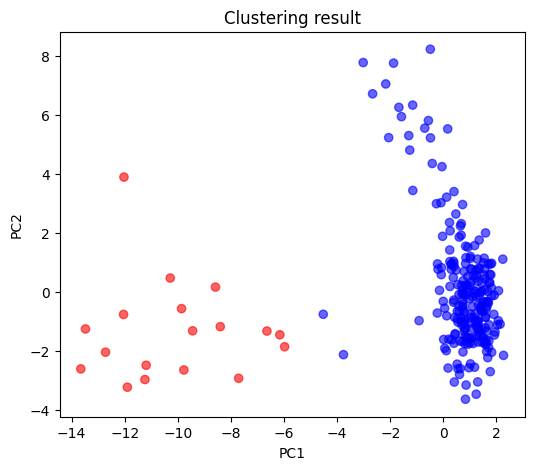

In [15]:
import matplotlib.pyplot as plt

# クラスタごとに色を設定
colors = ['blue' if lbl == 0 else 'red' for lbl in labels]

plt.figure(figsize=(6,5))
plt.scatter(features_2d[:,0], features_2d[:,1], c=colors, alpha=0.6)
plt.title('Clustering result')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## 6. 量子クラスタリング

次に、`qklearn` を用いた量子クラスタリングを実行します。
ここでは Amplify クライアントを利用し、PCA 後の特徴量に対して **BinaryClustering** を適用します。

この段階では、まず `qklearn` が提供する通常の実行方法でクラスタリングを行い、
後の節で同じ問題を **QUBO として取り出して別ソルバーで解く** ための基準結果として使います。

つまり、この節の結果は次の比較の基準になります。

- `qklearn` が直接返すクラスタリング結果
- `qklearn` が生成した QUBO を別ソルバーで解いた結果


In [ ]:
## 量子クラスタリング
from amplify import FixstarsClient
from datetime import timedelta
from qklearn.utils import read_token
from qklearn.cluster import CombinatorialClustering, BinaryClustering, KernelClustering

client = FixstarsClient()
token = "YOUR TOKEN"
client.token = token
client.parameters.timeout = timedelta(milliseconds=1000)

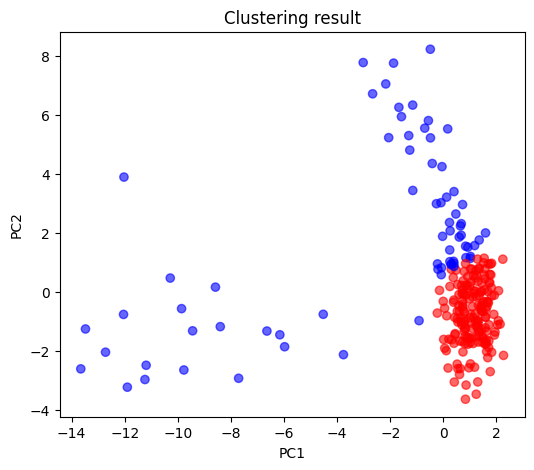

In [ ]:
qcl = BinaryClustering()
#qcl = CombinatorialClustering(n_clusters=2)
labels_qcl = qcl.fit_predict(features_2d, client)

# クラスタごとに色を設定
colors = ['blue' if lbl == 0 else 'red' for lbl in labels_qcl]

plt.figure(figsize=(6,5))
plt.scatter(features_2d[:,0], features_2d[:,1], c=colors, alpha=0.6)
plt.title('Clustering result')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

## 7. qudas を用いた複数ソルバー比較

ここからは、`qklearn` が内部で定式化した QUBO を取り出し、`qudas` を介して複数のソルバーで解きます。

`qudas` を用いる利点は、QUBO をいったん共通表現に変換してから、各ソルバー向けの形式へ変換できることです。
これにより、同じ最適化問題に対して

- **Amplify**
- **Neal**

といった複数のソルバーを切り替えて実行し、その結果を公平に比較できます。

最新の `qudas` では依存関係の衝突が解消されているため、本ノートブックでは外部スクリプトを介さず、同一の実行環境・同一ノートブック内でそのまま比較を行います。


### 7.1 qudas を用いたソルバー比較の概要
QUDAS を用いることで、QUBO 行列をいったん共通表現 `QuData` に変換し、
そこから各ソルバー向けの形式へ変換できます。

このため、利用者はソルバーごとの入力形式の違いを強く意識せずに、
`solver="amplify"` や `solver="neal"` のように指定を切り替えるだけで、
同じ最適化問題を複数のソルバーで比較できます。

### 7.2 qudas 呼び出し用の共通関数

ここでは、`qklearn` から得た QUBO 行列を受け取り、`qudas` を介して各ソルバーで解くための共通関数を定義します。

処理の流れは次のとおりです。

1. `qklearn` から得た QUBO 行列を `QuData` に変換する
2. ソルバー名に応じて `Amplify` または `Neal` 用の形式へ変換する
3. 最良解のエネルギーと変数値を共通形式で返す

このようにしておくことで、ノートブック側では **「QUBO とソルバー名を渡す」** だけで、
Amplify と Neal の両方を同じインタフェースで実行できます。


In [18]:
from qudas import QuData
from amplify import solve, FixstarsClient
from neal import SimulatedAnnealingSampler


def qubo_array_to_qudata(qubo_array):
    """
    NumPy 配列として表現された QUBO 行列を、
    qudas の共通データ形式 QuData に変換する。
    """
    return QuData.input().from_array(np.asarray(qubo_array, dtype=float))


def normalize_values(values):
    """
    ソルバーごとに返り値の型が異なるため、
    後段で扱いやすい Python 組み込み型へ変換する。
    """
    if hasattr(values, "items"):
        normalized = {}
        for k, v in values.items():
            normalized[str(k)] = int(v)
        return normalized

    if isinstance(values, dict):
        return {str(k): int(v) for k, v in values.items()}

    try:
        return [int(v) for v in values]
    except TypeError:
        return values


def solve_with_amplify(qudata, solver_params):
    """
    qudas の QuData から Amplify 用の目的関数へ変換し、
    Amplify ソルバーで最適化を実行する。
    """
    f = qudata.to_amplify()

    token = solver_params["token"]
    time_limit_ms = int(solver_params.get("time_limit_ms", 1000))

    client = FixstarsClient()
    client.token = token
    client.proxy = "http://proxy.chodai.co.jp:8080"
    client.parameters.timeout = timedelta(milliseconds=time_limit_ms)

    result = solve(f, client)
    best = result.best

    return {
        "solver": "amplify",
        "values": normalize_values(best.values),
        "energy": float(best.objective),
        "status": "ok",
    }


def solve_with_neal(qudata, solver_params):
    """
    qudas の QuData から dimod の BQM へ変換し、
    Neal（シミュレーテッドアニーリング）で最適化を実行する。
    """
    bqm = qudata.to_dimod_bqm()
    num_reads = int(solver_params.get("num_reads", 100))

    sampler = SimulatedAnnealingSampler()
    sampleset = sampler.sample(bqm, num_reads=num_reads)
    best = sampleset.first

    return {
        "solver": "neal",
        "values": normalize_values(best.sample),
        "energy": float(best.energy),
        "status": "ok",
    }


def solve_qubo_with_qudas(qubo_array, solver, solver_params=None):
    """
    QUBO 行列を qudas の共通表現へ変換し、
    指定したソルバーで解くための共通関数。
    """
    solver_params = solver_params or {}
    qudata = qubo_array_to_qudata(qubo_array)

    if solver == "amplify":
        return solve_with_amplify(qudata, solver_params)
    elif solver == "neal":
        return solve_with_neal(qudata, solver_params)
    else:
        raise ValueError(f"Unsupported solver: {solver}")


### 7.3 Amplify による QUBO の求解

最初に、`qklearn` が生成した QUBO を **Amplify** で解きます。
ここでは API トークンと時間制限を与え、最良解のエネルギーと変数の値を取得します。

この結果は、後で `qklearn` 本体の結果や Neal の結果と比較する対象になります。


#### 7.3.1 Amplify で解いてみましょう

In [ ]:
# qukit-learn で生成した QUBO 行列を取り出す
qubo_array = qcl.indexed_qubo

# solver を "amplify" にするだけで Amplify を利用できる
res_amplify = solve_qubo_with_qudas(
    qubo_array,
    solver="amplify",
    solver_params={
        "token": token,          # Amplify API トークン
        "time_limit_ms": 1000,   # 計算時間上限（ミリ秒）
    },
)

print("solver:", res_amplify["solver"])
print("energy:", res_amplify["energy"])
print("values:", res_amplify["values"])

solver: amplify
energy: -153698.6690923588
values: {'q_0': 0, 'q_1': 0, 'q_10': 1, 'q_100': 1, 'q_101': 1, 'q_102': 1, 'q_103': 0, 'q_104': 1, 'q_105': 0, 'q_106': 0, 'q_107': 1, 'q_108': 1, 'q_109': 0, 'q_11': 1, 'q_110': 1, 'q_111': 1, 'q_112': 1, 'q_113': 1, 'q_114': 0, 'q_115': 1, 'q_116': 0, 'q_117': 1, 'q_118': 1, 'q_119': 1, 'q_12': 1, 'q_120': 1, 'q_121': 1, 'q_122': 1, 'q_123': 1, 'q_124': 0, 'q_125': 0, 'q_126': 1, 'q_127': 1, 'q_128': 0, 'q_129': 0, 'q_13': 1, 'q_130': 0, 'q_131': 1, 'q_132': 0, 'q_133': 0, 'q_134': 1, 'q_135': 1, 'q_136': 1, 'q_137': 1, 'q_138': 1, 'q_139': 1, 'q_14': 0, 'q_140': 0, 'q_141': 0, 'q_142': 1, 'q_143': 1, 'q_144': 1, 'q_145': 0, 'q_146': 0, 'q_147': 1, 'q_148': 1, 'q_149': 1, 'q_15': 1, 'q_150': 1, 'q_151': 1, 'q_152': 0, 'q_153': 0, 'q_154': 1, 'q_155': 1, 'q_156': 1, 'q_157': 1, 'q_158': 1, 'q_159': 1, 'q_16': 1, 'q_160': 1, 'q_161': 1, 'q_162': 1, 'q_163': 1, 'q_164': 1, 'q_165': 1, 'q_166': 1, 'q_167': 1, 'q_168': 1, 'q_169': 1, 'q_17': 1, 

### 7.4 Neal による QUBO の求解

次に、同じ QUBO 行列を **Neal** で解きます。
ここで変更するのはソルバー名とソルバー固有パラメータだけであり、
**同じ最適化問題を別ソルバーで解く** という比較の形になっています。

これにより、定式化は共通のまま、ソルバーの違いによる解の差を確認できます。


In [20]:
# 同じ QUBO 行列に対して、
# solver 名を "neal" に変えるだけで Neal に切り替えられる
res_neal = solve_qubo_with_qudas(
    qubo_array,
    solver="neal",
    solver_params={
        "num_reads": 100,   # サンプリング回数
    },
)

print("solver:", res_neal["solver"])
print("energy:", res_neal["energy"])
print("values:", res_neal["values"])

solver: neal
energy: -153698.6690923603
values: {'q_0': 1, 'q_1': 1, 'q_10': 0, 'q_100': 0, 'q_101': 0, 'q_102': 0, 'q_103': 1, 'q_104': 0, 'q_105': 1, 'q_106': 1, 'q_107': 0, 'q_108': 0, 'q_109': 1, 'q_11': 0, 'q_110': 0, 'q_111': 0, 'q_112': 0, 'q_113': 0, 'q_114': 1, 'q_115': 0, 'q_116': 1, 'q_117': 0, 'q_118': 0, 'q_119': 0, 'q_12': 0, 'q_120': 0, 'q_121': 0, 'q_122': 0, 'q_123': 0, 'q_124': 1, 'q_125': 1, 'q_126': 0, 'q_127': 0, 'q_128': 1, 'q_129': 1, 'q_13': 0, 'q_130': 1, 'q_131': 0, 'q_132': 1, 'q_133': 1, 'q_134': 0, 'q_135': 0, 'q_136': 0, 'q_137': 0, 'q_138': 0, 'q_139': 0, 'q_14': 1, 'q_140': 1, 'q_141': 1, 'q_142': 0, 'q_143': 0, 'q_144': 0, 'q_145': 1, 'q_146': 1, 'q_147': 0, 'q_148': 0, 'q_149': 0, 'q_15': 0, 'q_150': 0, 'q_151': 0, 'q_152': 1, 'q_153': 1, 'q_154': 0, 'q_155': 0, 'q_156': 0, 'q_157': 0, 'q_158': 0, 'q_159': 0, 'q_16': 0, 'q_160': 0, 'q_161': 0, 'q_162': 0, 'q_163': 0, 'q_164': 0, 'q_165': 0, 'q_166': 0, 'q_167': 0, 'q_168': 0, 'q_169': 0, 'q_17': 0, 'q_

### 7.5 ソルバーの出力を配列へ変換する

`qudas` から返ってくる解は、ソルバーによって辞書形式または辞書ライクな形式になるため、比較や可視化に使いやすいように NumPy 配列へ変換します。
変数番号順に並べ替えておくことで、Amplify と Neal の出力を同じ形式で扱えるようになります。


解(辞書形式)をnumpy配列に変換する関数を定義しておきます。

In [21]:
def values_to_array(values_dict):
    """Amplify の Values(dict) → 変数番号順の numpy 配列"""
    # key は Poly(q_0) みたいなオブジェクトなので、str(key) -> "q_0"
    items = sorted(
        values_dict.items(),
        key=lambda kv: int(str(kv[0]).split("_")[-1])  # "q_3" -> 3
    )
    return np.array([v for _, v in items])


### 7.6 4 手法の結果を同じ形式にそろえる

ここからは、次の 4 つの結果を比較します。

1. **scikit-learn の KMeans**
2. **qklearn の量子クラスタリング**
3. **qklearn の QUBO を Amplify で解いた結果**
4. **qklearn の QUBO を Neal で解いた結果**

まずは各手法の出力を 1 次元のラベル配列としてそろえ、長さや値域が一致しているかを確認します。
この整形を行っておくことで、後続の評価や可視化を共通処理で行えるようになります。


In [22]:
# === Amplify / Neal の解を配列化 =======================================
vals_amplify = values_to_array(res_amplify["values"])
vals_neal = values_to_array(res_neal["values"])

print("vals_amplify shape:", vals_amplify.shape)
print("vals_neal shape   :", vals_neal.shape)

print("vals_amplify[:20] =", vals_amplify[:20])
print("vals_neal[:20]    =", vals_neal[:20])

vals_amplify shape: (249,)
vals_neal shape   : (249,)
vals_amplify[:20] = [0 0 1 1 1 0 0 1 1 0 1 1 1 1 0 1 1 1 1 1]
vals_neal[:20]    = [1 1 0 0 0 1 1 0 0 1 0 0 0 0 1 0 0 0 0 0]


In [23]:
# === 4手法のラベルをそろえる ==========================================
labels_sklearn = np.asarray(labels).astype(int)
labels_qklearn = np.asarray(labels_qcl).astype(int)
labels_amplify = np.asarray(vals_amplify).astype(int)
labels_neal = np.asarray(vals_neal).astype(int)

print("sklearn unique :", np.unique(labels_sklearn))
print("qklearn unique :", np.unique(labels_qklearn))
print("amplify unique :", np.unique(labels_amplify))
print("neal unique    :", np.unique(labels_neal))

print("lengths:",
      len(labels_sklearn),
      len(labels_qklearn),
      len(labels_amplify),
      len(labels_neal),
      " / true =", len(true_labels))

sklearn unique : [0 1]
qklearn unique : [0 1]
amplify unique : [0 1]
neal unique    : [0 1]
lengths: 249 249 249 249  / true = 249


In [24]:
# === 整合性チェック ====================================================
methods_raw = {
    "sklearn": labels_sklearn,
    "qklearn": labels_qklearn,
    "qklearn+amplify": labels_amplify,
    "qklearn+neal": labels_neal,
}

for name, arr in methods_raw.items():
    arr = np.asarray(arr)
    print(f"[{name}]")
    print("  shape :", arr.shape)
    print("  unique:", np.unique(arr))
    print("  first10:", arr[:10])
    print()

[sklearn]
  shape : (249,)
  unique: [0 1]
  first10: [0 0 0 0 0 0 0 0 0 0]

[qklearn]
  shape : (249,)
  unique: [0 1]
  first10: [0 0 1 1 1 0 0 1 1 0]

[qklearn+amplify]
  shape : (249,)
  unique: [0 1]
  first10: [0 0 1 1 1 0 0 1 1 0]

[qklearn+neal]
  shape : (249,)
  unique: [0 1]
  first10: [1 1 0 0 0 1 1 0 0 1]



### 7.7 ラベル向きの補正と評価指標の集計

クラスタリングでは、クラスタ ID の 0 と 1 に意味は固定されていません。
そのため、ある手法では「0 が正常、1 が異常」、別の手法ではその逆になることがあります。

ここでは、真値ラベルと照合して必要に応じてラベルを反転し、
比較しやすい形にそろえたうえで次の指標を集計します。

- Accuracy
- Precision
- Recall
- F1-score
- 混同行列

この処理により、4 手法を同じ基準で比較できるようにします。


In [25]:
# === ラベル反転を吸収する評価用ユーティリティ ==========================
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import pandas as pd
import numpy as np

def align_binary_labels(y_true, y_pred):
    """
    y_pred と 1-y_pred を比較し、accuracy が高い方を返す
    """
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)

    acc_original = accuracy_score(y_true, y_pred)
    acc_flipped = accuracy_score(y_true, 1 - y_pred)

    if acc_flipped > acc_original:
        return 1 - y_pred, True
    else:
        return y_pred, False

def summarize_method(y_true, y_pred, method_name):
    y_aligned, flipped = align_binary_labels(y_true, y_pred)

    row = {
        "method": method_name,
        "flipped": flipped,
        "accuracy": accuracy_score(y_true, y_aligned),
        "precision": precision_score(y_true, y_aligned, zero_division=0),
        "recall": recall_score(y_true, y_aligned, zero_division=0),
        "f1": f1_score(y_true, y_aligned, zero_division=0),
    }
    cm = confusion_matrix(y_true, y_aligned, labels=[0, 1])
    return row, y_aligned, cm

In [26]:
# === 4手法を一括評価して表にまとめる ==================================
rows = []
aligned_results = {}
conf_mats = {}

for name, pred in methods_raw.items():
    row, pred_aligned, cm = summarize_method(true_labels, pred, name)
    rows.append(row)
    aligned_results[name] = pred_aligned
    conf_mats[name] = cm

df_metrics = pd.DataFrame(rows).sort_values(["f1", "accuracy"], ascending=False).reset_index(drop=True)
df_metrics

,method,flipped,accuracy,precision,recall,f1
0,sklearn,False,0.991968,1.00000,0.9,0.947368
1,qklearn,True,0.795181,0.28169,1.0,0.439560
2,qklearn+amplify,True,0.795181,0.28169,1.0,0.439560
3,qklearn+neal,False,0.795181,0.28169,1.0,0.439560


In [27]:
# === 各手法の混同行列を表示 ============================================
for name in aligned_results:
    print("=" * 60)
    print(name)
    print("Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):")
    print(conf_mats[name])
    print()

sklearn
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[229   0]
 [  2  18]]

qklearn
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]

qklearn+amplify
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]

qklearn+neal
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]



### 7.8 4 手法の可視化と比較

評価表だけでは分かりにくい部分を補うため、PCA の 2 次元空間上で各手法の結果を可視化します。
同じデータに対して色分けの違いを並べて確認することで、

- どの手法が似た分割をしているか
- 真値に近い分かれ方になっているか
- 外れ値的なサンプルがどのように扱われているか

を直感的に読み取ることができます。


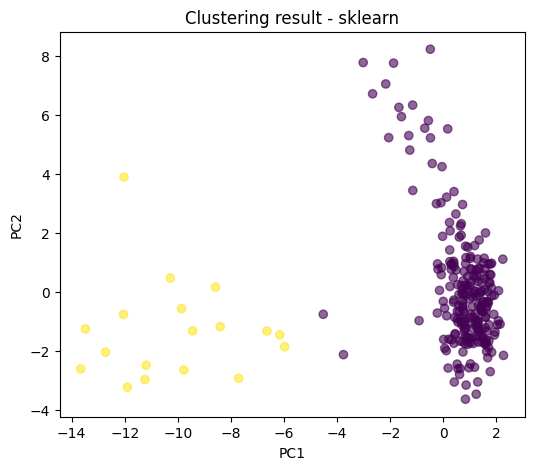

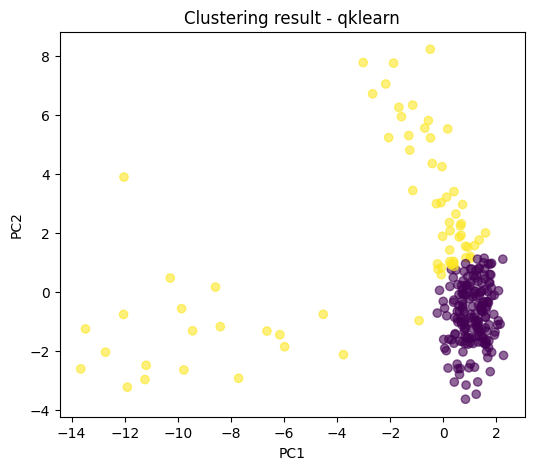

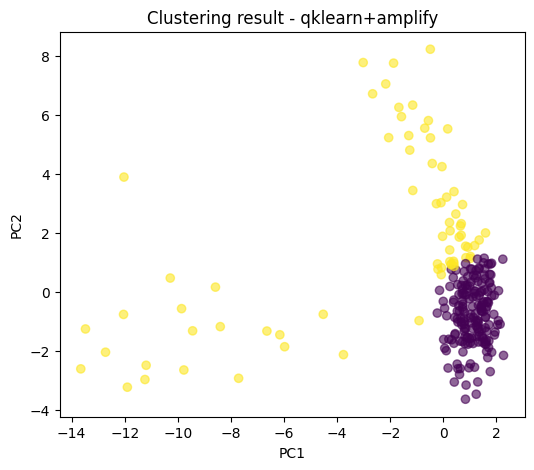

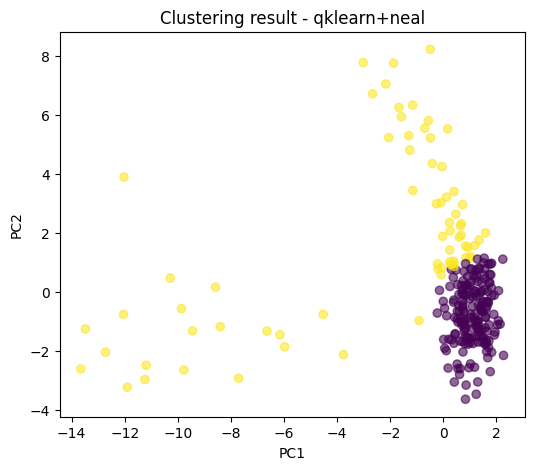

In [28]:
# === PCA散布図で4手法を比較 ============================================
import matplotlib.pyplot as plt

for name, pred_aligned in aligned_results.items():
    plt.figure(figsize=(6, 5))
    plt.scatter(features_2d[:, 0], features_2d[:, 1], c=pred_aligned, alpha=0.6)
    plt.title(f"Clustering result - {name}")
    plt.xlabel("PC1")
    plt.ylabel("PC2")
    plt.show()

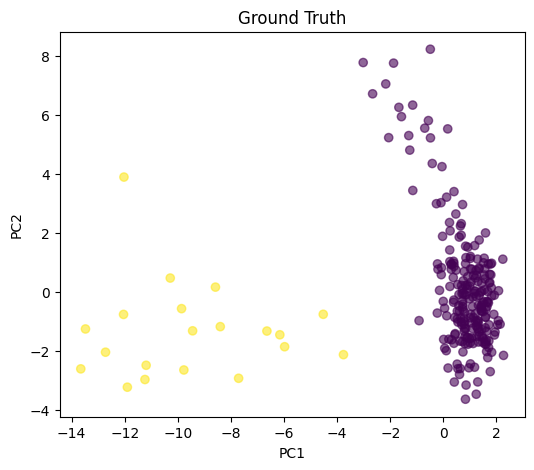

In [29]:
# === 真値ラベルの散布図 ================================================
plt.figure(figsize=(6, 5))
plt.scatter(features_2d[:, 0], features_2d[:, 1], c=true_labels, alpha=0.6)
plt.title("Ground Truth")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()

### 7.9 距離ベース異常スコアと手法間一致率

クラスタ ID のみを見るだけでなく、正常クラスタ中心からの距離を異常スコアとして利用することで、
より連続的な異常度の評価も行えます。

ここでは、各手法について

- 多数決で正常クラスタを決める
- 正常クラスタ中心からの距離を異常スコアとして計算する
- ROC-AUC を含む評価を行う

という流れを実行します。

さらに、手法間のラベル一致率を求めることで、
`qklearn` の結果と Amplify / Neal の結果がどの程度似ているかも確認します。


== sklearn (majority normal + distance score) ==
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[229   0]
 [  2  18]]
Accuracy:  0.9920
Precision: 1.0000  Recall: 0.9000  F1: 0.9474
ROC-AUC:  0.9910


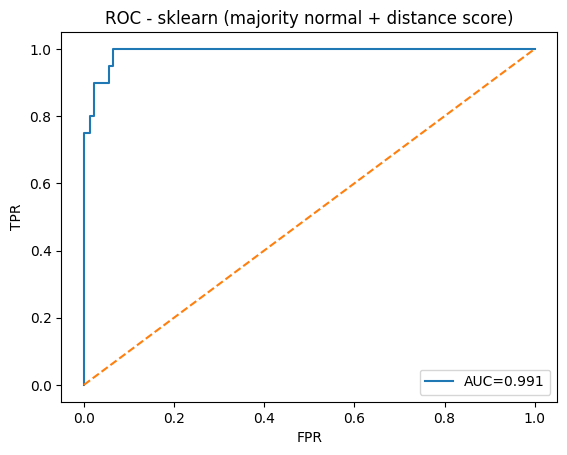

== qklearn (majority normal + distance score) ==
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]
Accuracy:  0.7952
Precision: 0.2817  Recall: 1.0000  F1: 0.4396
ROC-AUC:  0.9882


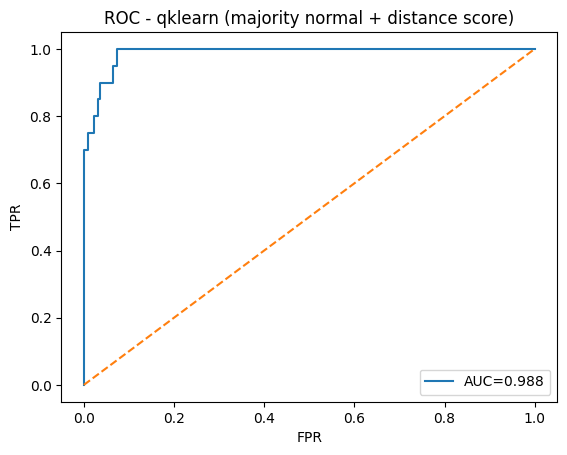

== qklearn+amplify (majority normal + distance score) ==
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]
Accuracy:  0.7952
Precision: 0.2817  Recall: 1.0000  F1: 0.4396
ROC-AUC:  0.9882


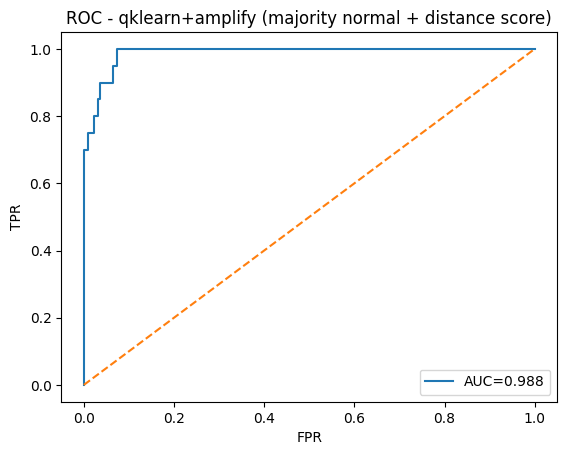

== qklearn+neal (majority normal + distance score) ==
Confusion Matrix (rows=true [Normal, Anomaly], cols=pred):
[[178  51]
 [  0  20]]
Accuracy:  0.7952
Precision: 0.2817  Recall: 1.0000  F1: 0.4396
ROC-AUC:  0.9882


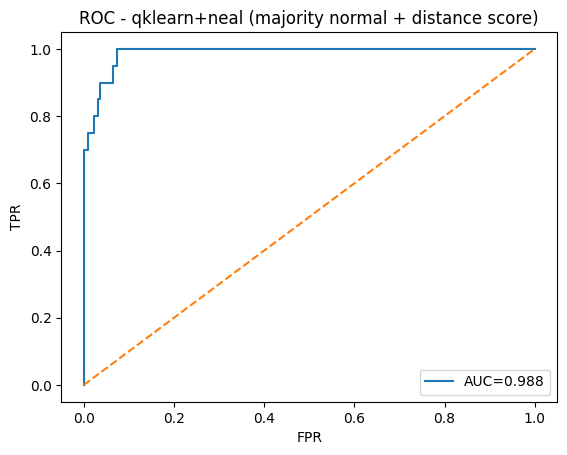

,method,majority_normal_cluster,accuracy,precision,recall,f1
0,sklearn,0,0.991968,1.00000,0.9,0.947368
1,qklearn,0,0.795181,0.28169,1.0,0.439560
2,qklearn+amplify,0,0.795181,0.28169,1.0,0.439560
3,qklearn+neal,0,0.795181,0.28169,1.0,0.439560


In [30]:
# === 多数決で正常クラスタを決め、距離ベース異常スコアを評価 ============
score_rows = []

for name, pred_aligned in aligned_results.items():
    majority_cluster, y_pred_majority = decide_normal_by_majority(pred_aligned)
    scores = anomaly_scores_by_distance(features_2d, pred_aligned, majority_cluster)

    result = evaluate_predictions(
        true_labels,
        y_pred_majority,
        scores=scores,
        title=f"{name} (majority normal + distance score)"
    )

    score_rows.append({
        "method": name,
        "majority_normal_cluster": int(majority_cluster),
        "accuracy": result["accuracy"],
        "precision": result["precision"],
        "recall": result["recall"],
        "f1": result["f1"],
    })

df_score_metrics = pd.DataFrame(score_rows).sort_values(["f1", "accuracy"], ascending=False).reset_index(drop=True)
df_score_metrics

In [31]:
# === 手法間の一致率を確認 ==============================================
method_names = list(aligned_results.keys())

agreement_rows = []
for i in range(len(method_names)):
    for j in range(i + 1, len(method_names)):
        m1 = method_names[i]
        m2 = method_names[j]
        a1 = aligned_results[m1]
        a2 = aligned_results[m2]
        agreement = np.mean(a1 == a2)
        agreement_rows.append({
            "method_1": m1,
            "method_2": m2,
            "agreement": agreement,
        })

df_agreement = pd.DataFrame(agreement_rows).sort_values("agreement", ascending=False).reset_index(drop=True)
df_agreement

,method_1,method_2,agreement
0,qklearn,qklearn+neal,1.000000
1,qklearn,qklearn+amplify,1.000000
2,qklearn+amplify,qklearn+neal,1.000000
3,sklearn,qklearn,0.787149
4,sklearn,qklearn+amplify,0.787149
5,sklearn,qklearn+neal,0.787149


### 7.10 異常画像の例示と結果の要約

最後に、比較結果の中で指標がもっとも良かった手法を選び、
異常と判定された画像の例を表示します。

数値指標だけでなく、実際の画像を確認することで、
クラスタリング結果がどのようなサンプルを異常として拾っているかを理解しやすくなります。
あわせて、4 手法の比較結果を表形式でまとめ、ここまでの流れを振り返ります。


best_method: sklearn
predicted anomalies: 18


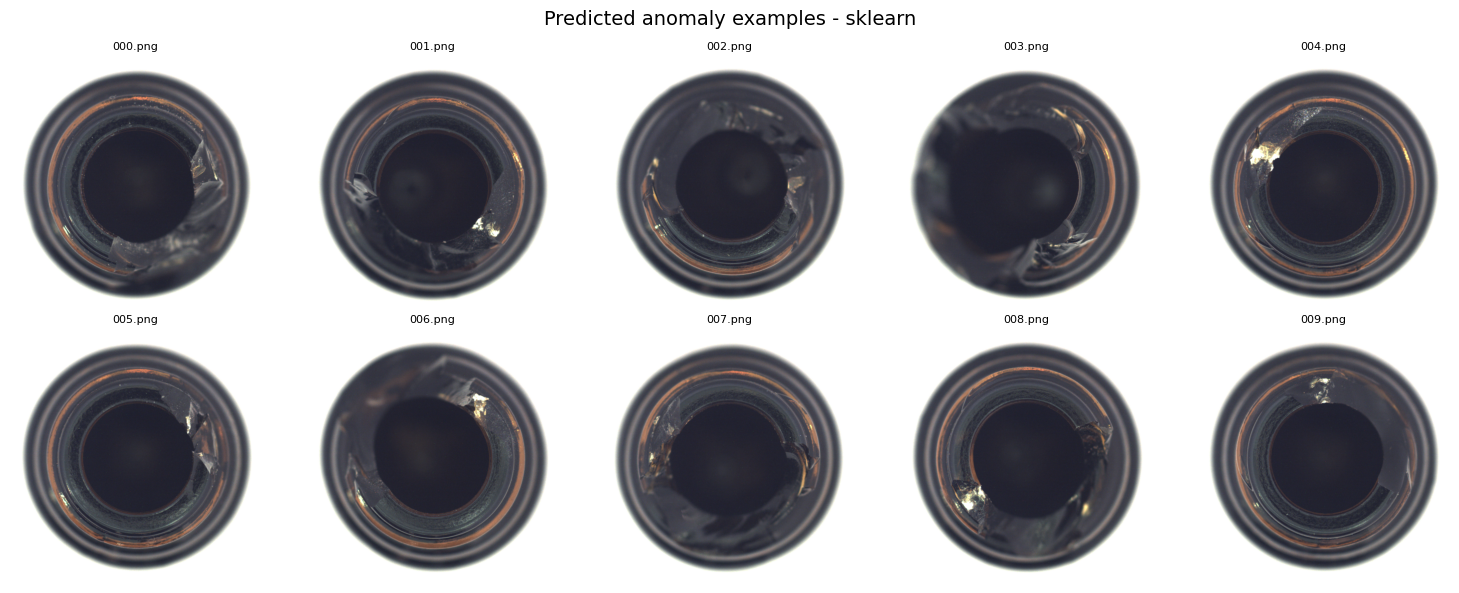

In [32]:
# === 指標が最良の手法で、異常判定画像を表示 ============================
import math
from PIL import Image
from pathlib import Path

best_method = df_metrics.iloc[0]["method"]
best_pred = aligned_results[best_method]

anomaly_paths = [path for path, pred in zip(all_images, best_pred) if pred == 1]

print("best_method:", best_method)
print("predicted anomalies:", len(anomaly_paths))

n_show = min(10, len(anomaly_paths))
cols = 5
rows = math.ceil(n_show / cols)

plt.figure(figsize=(15, 3 * rows))
for i, path in enumerate(anomaly_paths[:n_show], 1):
    img = Image.open(path)
    plt.subplot(rows, cols, i)
    plt.imshow(img)
    plt.title(Path(path).name, fontsize=8)
    plt.axis("off")

plt.suptitle(f"Predicted anomaly examples - {best_method}", fontsize=14)
plt.tight_layout()
plt.show()

In [33]:
# === 比較結果の要約 ====================================================
best_method = df_metrics.iloc[0]["method"]
best_f1 = df_metrics.iloc[0]["f1"]
best_acc = df_metrics.iloc[0]["accuracy"]

print("4手法比較の要約")
print("------------------------------")
print(f"最も良かった手法: {best_method}")
print(f"Accuracy: {best_acc:.4f}")
print(f"F1-score: {best_f1:.4f}")
print()
print("詳細指標:")
display(df_metrics)

4手法比較の要約
------------------------------
最も良かった手法: sklearn
Accuracy: 0.9920
F1-score: 0.9474

詳細指標:


,method,flipped,accuracy,precision,recall,f1
0,sklearn,False,0.991968,1.00000,0.9,0.947368
1,qklearn,True,0.795181,0.28169,1.0,0.439560
2,qklearn+amplify,True,0.795181,0.28169,1.0,0.439560
3,qklearn+neal,False,0.795181,0.28169,1.0,0.439560



## 10. Amplify-BBOpt によるブラックボックス最適化

ここまでの章では、PCA により特徴量を低次元化した後、sklearn、qklearn、および qklearn から生成した QUBO を Amplify / Neal で解く方法を比較してきました。

本章では、これとは別の観点から異常検知性能の改善を試みます。具体的には、距離ベースの異常判定器に対して、PCA の次元数、距離尺度、正常中心の決め方、しきい値の与え方などを探索対象とし、評価データに対する異常検知性能が高くなるように設定を最適化します。

ここで用いる `amplify-bbopt-ext` は、Fixstars Amplify BBOpt を基盤としたブラックボックス離散最適化の拡張ライブラリです。本ノートブックでは、このライブラリを用いて「評価値だけが得られる関数」を目的関数として扱い、最適なパラメータ設定を探索します。

In [34]:
from amplify_bbopt_ext.latest_filter import run

### 10.1 最適化対象の設定

本章では、距離ベース異常検知器の設定をブラックボックス最適化の対象とします。

具体的には、以下のようなパラメータを組み合わせて探索します。

- PCA の次元数
- 距離尺度（ユークリッド距離またはコサイン距離）
- 正常データの中心をどのように定めるか
- 異常判定のしきい値をどのように決めるか
- しきい値に対応する実数パラメータ

これらの組合せごとに異常検知を実行し、評価データに対する F1 スコアを求めます。ブラックボックス最適化では、この評価値が最も良くなる設定を探索します。

In [35]:
# 探索候補の定義
PCA_CHOICES = [16, 24, 32, 48, 64]
METRIC_CHOICES = ["euclidean", "cosine"]
CENTER_CHOICES = ["mean", "medoid"]
THR_MODE_CHOICES = ["percentile", "zscore", "fixed_margin"]

print("PCA_CHOICES      =", PCA_CHOICES)
print("METRIC_CHOICES   =", METRIC_CHOICES)
print("CENTER_CHOICES   =", CENTER_CHOICES)
print("THR_MODE_CHOICES =", THR_MODE_CHOICES)

PCA_CHOICES      = [16, 24, 32, 48, 64]
METRIC_CHOICES   = ['euclidean', 'cosine']
CENTER_CHOICES   = ['mean', 'medoid']
THR_MODE_CHOICES = ['percentile', 'zscore', 'fixed_margin']


### 10.2 距離ベース異常検知の補助関数

ここでは、ブラックボックス最適化の内部で繰り返し利用する補助関数を定義します。

まず、正常データから「中心」を求めます。中心の定め方としては、各特徴量の平均ベクトルを用いる方法と、正常データの中から代表点を 1 つ選ぶ medoid の方法を用います。

次に、各サンプルと正常中心の距離を計算します。距離尺度としては、ユークリッド距離とコサイン距離を比較できるようにします。

さらに、正常データの距離分布に基づいて異常判定のしきい値を求めます。しきい値の与え方としては、パーセンタイル、平均と標準偏差による z-score 型、固定マージン型を用意します。

これらの関数を組み合わせることで、「あるパラメータ設定に対して異常検知を実行し、その性能を評価する」という処理を目的関数として扱えるようになります。

In [36]:
def compute_center(X_normal, center_mode="mean", metric="euclidean"):
    """
    正常データから中心ベクトルを求める
    center_mode:
        - "mean"   : 平均ベクトル
        - "medoid" : 正常データ中で総距離が最小のサンプル
    """
    X_normal = np.asarray(X_normal)

    if center_mode == "mean":
        return X_normal.mean(axis=0)

    if center_mode == "medoid":
        n = len(X_normal)
        if n == 1:
            return X_normal[0]

        if metric == "euclidean":
            diff = X_normal[:, None, :] - X_normal[None, :, :]
            dist_mat = np.sqrt((diff ** 2).sum(axis=2))
        elif metric == "cosine":
            norms = np.linalg.norm(X_normal, axis=1, keepdims=True)
            Xn = X_normal / np.clip(norms, 1e-12, None)
            sim = Xn @ Xn.T
            dist_mat = 1.0 - sim
        else:
            raise ValueError(f"Unknown metric: {metric}")

        medoid_idx = np.argmin(dist_mat.sum(axis=1))
        return X_normal[medoid_idx]

    raise ValueError(f"Unknown center_mode: {center_mode}")


def compute_distance_to_center(X, center, metric="euclidean"):
    """
    各サンプルと中心との距離を返す
    """
    X = np.asarray(X)
    center = np.asarray(center)

    if metric == "euclidean":
        return np.sqrt(((X - center) ** 2).sum(axis=1))

    if metric == "cosine":
        x_norm = np.linalg.norm(X, axis=1)
        c_norm = np.linalg.norm(center)
        sim = (X @ center) / np.clip(x_norm * c_norm, 1e-12, None)
        return 1.0 - sim

    raise ValueError(f"Unknown metric: {metric}")


def determine_threshold(normal_distances, thr_mode="percentile", thr_value=95.0):
    """
    正常データの距離分布からしきい値を決める
    thr_mode:
        - "percentile"  : パーセンタイル
        - "zscore"      : mean + thr_value * std
        - "fixed_margin": max + thr_value
    """
    normal_distances = np.asarray(normal_distances)

    if thr_mode == "percentile":
        return np.percentile(normal_distances, thr_value)

    if thr_mode == "zscore":
        mu = normal_distances.mean()
        sigma = normal_distances.std()
        return mu + thr_value * sigma

    if thr_mode == "fixed_margin":
        return normal_distances.max() + thr_value

    raise ValueError(f"Unknown thr_mode: {thr_mode}")


def predict_anomaly_labels(distances, threshold):
    """
    距離がしきい値を超えたら異常(1)、そうでなければ正常(0)
    """
    distances = np.asarray(distances)
    return (distances > threshold).astype(int)

In [37]:
# 簡単な動作確認
X_dummy = np.array([
    [0.0, 0.0],
    [0.1, 0.0],
    [0.0, 0.1],
    [3.0, 3.0],
])

center_mean = compute_center(X_dummy[:3], center_mode="mean", metric="euclidean")
dists = compute_distance_to_center(X_dummy, center_mean, metric="euclidean")
thr = determine_threshold(dists[:3], thr_mode="percentile", thr_value=95)
pred = predict_anomaly_labels(dists, thr)

print("center_mean =", center_mean)
print("distances   =", dists)
print("threshold   =", thr)
print("pred        =", pred)

center_mean = [0.03333333 0.03333333]
distances   = [0.04714045 0.0745356  0.0745356  4.19550024]
threshold   = 0.074535599249993
pred        = [0 0 0 1]


### 10.3 1組のパラメータで異常検知を実行する関数

ここでは、与えられたパラメータ設定に対して、実際に異常検知を実行し、その性能を評価する関数を定義します。

処理の流れは以下のとおりです。

1. 学習用正常データと評価用データをまとめて PCA に入力し、指定された次元数に圧縮します。
2. 圧縮後の学習用正常データから正常中心を求めます。
3. 正常中心からの距離を計算します。
4. 学習用正常データの距離分布からしきい値を決定します。
5. 評価用データに対して正常／異常を判定し、Accuracy、Precision、Recall、F1 を計算します。

ブラックボックス最適化では、この関数の返す F1 スコアをもとに、より良い設定を探索していきます。

In [38]:
def run_distance_anomaly_detection(
    train_good_features,
    eval_features,
    eval_labels,
    pca_dim=32,
    metric="euclidean",
    center_mode="mean",
    thr_mode="percentile",
    thr_value=95.0,
):
    """
    1組のパラメータ設定で距離ベース異常検知を実行し、
    評価結果を辞書で返す
    """
    train_good_features = np.asarray(train_good_features)
    eval_features = np.asarray(eval_features)
    eval_labels = np.asarray(eval_labels).astype(int)

    # PCA 次元数は元の特徴次元やサンプル数を超えないように調整
    max_valid_dim = min(
        pca_dim,
        train_good_features.shape[1],
        len(np.vstack([train_good_features, eval_features]))
    )

    pca = PCA(n_components=max_valid_dim)

    all_features = np.vstack([train_good_features, eval_features])
    all_features_pca = pca.fit_transform(all_features)

    train_good_pca = all_features_pca[: len(train_good_features)]
    eval_pca = all_features_pca[len(train_good_features):]

    # 正常中心を計算
    center = compute_center(train_good_pca, center_mode=center_mode, metric=metric)

    # 距離計算
    train_distances = compute_distance_to_center(train_good_pca, center, metric=metric)
    eval_distances = compute_distance_to_center(eval_pca, center, metric=metric)

    # しきい値決定
    threshold = determine_threshold(train_distances, thr_mode=thr_mode, thr_value=thr_value)

    # 予測
    y_pred = predict_anomaly_labels(eval_distances, threshold)

    # 指標
    result = {
        "pca_dim": int(max_valid_dim),
        "metric": metric,
        "center_mode": center_mode,
        "thr_mode": thr_mode,
        "thr_value": float(thr_value),
        "threshold": float(threshold),
        "accuracy": accuracy_score(eval_labels, y_pred),
        "precision": precision_score(eval_labels, y_pred, zero_division=0),
        "recall": recall_score(eval_labels, y_pred, zero_division=0),
        "f1": f1_score(eval_labels, y_pred, zero_division=0),
        "y_pred": y_pred,
        "distances": eval_distances,
        "center": center,
        "train_distances": train_distances,
        "eval_features_pca": eval_pca,
    }
    return result

In [39]:
# BBopt 用に、既存ノートブックの変数から学習用・評価用データを切り出す
n_train_good = len(train_good)

X_train_good = features[:n_train_good]
X_eval = features[n_train_good:]
y_eval = np.asarray(true_labels[n_train_good:]).astype(int)

print("X_train_good shape:", X_train_good.shape)
print("X_eval shape      :", X_eval.shape)
print("y_eval shape      :", y_eval.shape)
print("eval normal count :", np.sum(y_eval == 0))
print("eval anomaly count:", np.sum(y_eval == 1))

X_train_good shape: (209, 1280)
X_eval shape      : (40, 1280)
y_eval shape      : (40,)
eval normal count : 20
eval anomaly count: 20


In [40]:
result_example = run_distance_anomaly_detection(
    train_good_features=X_train_good,
    eval_features=X_eval,
    eval_labels=y_eval,
    pca_dim=32,
    metric="euclidean",
    center_mode="mean",
    thr_mode="percentile",
    thr_value=95.0,
)

print("accuracy :", result_example["accuracy"])
print("precision:", result_example["precision"])
print("recall   :", result_example["recall"])
print("f1       :", result_example["f1"])
print("threshold:", result_example["threshold"])

accuracy : 0.975
precision: 0.9523809523809523
recall   : 1.0
f1       : 0.975609756097561
threshold: 7.617303371429443


### 10.4 ブラックボックス目的関数の定義

`amplify-bbopt-ext` のサンプルに合わせて、本ノートブックでもブラックボックス関数はビット列入力として定義します。

ここでは、最適化したいパラメータをそのまま実数で与えるのではなく、複数のビットに分解して表現します。各候補点は 0/1 のベクトルとして与えられ、そのビット列を復号して以下の設定に変換します。

- PCA の次元数
- 距離尺度
- 正常中心の定め方
- しきい値の決め方
- しきい値パラメータ

このようにして得られた設定で異常検知を実行し、評価データに対する F1 スコアを計算します。最適化では F1 を最大化したいため、目的関数は `-F1` を返すようにします。

In [41]:
from amplify_bbopt import BinaryVariable, blackbox

# ---- ビット割り当て ----
N_BITS_PCA = 3         # 0..7 を表現し、後で 0..4 に丸める
N_BITS_METRIC = 1      # 0..1
N_BITS_CENTER = 1      # 0..1
N_BITS_THR_MODE = 2    # 0..3 を表現し、後で 0..2 に丸める
N_BITS_THR_VALUE = 7   # 0..127 を 80.0..99.9 に写像

N_BITS_TOTAL = (
    N_BITS_PCA
    + N_BITS_METRIC
    + N_BITS_CENTER
    + N_BITS_THR_MODE
    + N_BITS_THR_VALUE
)

print("N_BITS_TOTAL =", N_BITS_TOTAL)


def bits_to_int(bits):
    """
    bits: 0/1 の配列
    先頭を上位ビットとして整数へ変換
    """
    bits = np.asarray(bits).astype(int).ravel()
    value = 0
    for b in bits:
        value = (value << 1) | int(b)
    return value


def scale_int_to_range(v, v_min, v_max, out_min, out_max):
    """
    整数 v in [v_min, v_max] を実数区間 [out_min, out_max] に線形写像
    """
    if v_max == v_min:
        return float(out_min)
    ratio = (v - v_min) / (v_max - v_min)
    return float(out_min + ratio * (out_max - out_min))


def decode_bitvector(x_bits):
    """
    14ビットの配列を、実際に使う探索パラメータへ復号する
    """
    x_bits = np.asarray(x_bits).astype(int).ravel()
    if len(x_bits) != N_BITS_TOTAL:
        raise ValueError(f"Expected {N_BITS_TOTAL} bits, but got {len(x_bits)}")

    pos = 0

    pca_raw = bits_to_int(x_bits[pos:pos + N_BITS_PCA])
    pos += N_BITS_PCA

    metric_raw = bits_to_int(x_bits[pos:pos + N_BITS_METRIC])
    pos += N_BITS_METRIC

    center_raw = bits_to_int(x_bits[pos:pos + N_BITS_CENTER])
    pos += N_BITS_CENTER

    thr_mode_raw = bits_to_int(x_bits[pos:pos + N_BITS_THR_MODE])
    pos += N_BITS_THR_MODE

    thr_value_int = bits_to_int(x_bits[pos:pos + N_BITS_THR_VALUE])
    pos += N_BITS_THR_VALUE

    pca_idx = int(np.clip(pca_raw, 0, len(PCA_CHOICES) - 1))
    metric_idx = int(np.clip(metric_raw, 0, len(METRIC_CHOICES) - 1))
    center_idx = int(np.clip(center_raw, 0, len(CENTER_CHOICES) - 1))
    thr_mode_idx = int(np.clip(thr_mode_raw, 0, len(THR_MODE_CHOICES) - 1))

    pca_dim = PCA_CHOICES[pca_idx]
    metric = METRIC_CHOICES[metric_idx]
    center_mode = CENTER_CHOICES[center_idx]
    thr_mode = THR_MODE_CHOICES[thr_mode_idx]

    # 7ビット整数を mode ごとの実数範囲へ写像
    if thr_mode == "percentile":
        thr_value = scale_int_to_range(thr_value_int, 0, 127, 80.0, 99.9)
    elif thr_mode == "zscore":
        thr_value = scale_int_to_range(thr_value_int, 0, 127, 0.5, 5.0)
    elif thr_mode == "fixed_margin":
        thr_value = scale_int_to_range(thr_value_int, 0, 127, 0.0, 5.0)
    else:
        raise ValueError(f"Unknown thr_mode: {thr_mode}")

    return {
        "pca_idx": pca_idx,
        "metric_idx": metric_idx,
        "center_idx": center_idx,
        "thr_mode_idx": thr_mode_idx,
        "thr_value_int": int(thr_value_int),
        "pca_dim": pca_dim,
        "metric": metric,
        "center_mode": center_mode,
        "thr_mode": thr_mode,
        "thr_value": float(thr_value),
    }


@blackbox
def bb_objective(
    x: list[bool] = [BinaryVariable() for _ in range(N_BITS_TOTAL)]
) -> float:
    """
    0/1 ビット列を受け取り、対応する異常検知設定で -F1 を返す
    """
    params = decode_bitvector(x)

    result = run_distance_anomaly_detection(
        train_good_features=X_train_good,
        eval_features=X_eval,
        eval_labels=y_eval,
        pca_dim=params["pca_dim"],
        metric=params["metric"],
        center_mode=params["center_mode"],
        thr_mode=params["thr_mode"],
        thr_value=params["thr_value"],
    )

    return -float(result["f1"])

N_BITS_TOTAL = 14


In [42]:
test_bits = np.array([0,1,0,  0,  1,  0,1,  1,0,1,0,1,1,0], dtype=int)

decoded = decode_bitvector(test_bits)
test_value = bb_objective(test_bits)

print("decoded params:")
for k, v in decoded.items():
    print(f"  {k}: {v}")

print("objective value =", test_value)
print("estimated F1    =", -test_value)
print("bb_objective type:", type(bb_objective))

decoded params:
  pca_idx: 2
  metric_idx: 0
  center_idx: 1
  thr_mode_idx: 1
  thr_value_int: 86
  pca_dim: 32
  metric: euclidean
  center_mode: medoid
  thr_mode: zscore
  thr_value: 3.547244094488189
objective value = -0.8648648648648649
estimated F1    = 0.8648648648648649
bb_objective type: <class 'amplify_bbopt.blackbox.blackbox.<locals>.BlackBoxFunc'>


### 10.5 最適化実行の準備

ここでは、ブラックボックス最適化を実行するためのクライアント設定を行います。

`amplify-bbopt-ext` では、FixstarsClient を用いてアニーリング計算の実行先やタイムアウトなどを設定し、そのクライアントを最適化ルーチンに渡します。

また、最適化では以下のような反復的な探索設定を与えます。

- 初期サンプル数
- 最適化の反復回数
- 学習エポック数
- アニーリング時に扱うサイズ制限
- 候補生成に関する設定

これらを小さめの値から開始することで、まずはノートブック上で動作確認を行い、その後必要に応じて探索回数を増やしていきます。

#### 10.5.1 初期サンプルの生成

ブラックボックス最適化では、探索の出発点となる初期サンプルの与え方が結果に影響します。初期サンプル数が少ない場合には、探索の履歴が短くなり、性能がどのように改善していくかが見えにくくなります。

そこで、ここでは初期サンプル数をやや多めに設定し、探索の過程を観察しやすくします。各候補は 0/1 のビット列として生成し、これを異常検知器のパラメータに復号して評価します。

In [43]:
# 初期サンプル集合を 0/1 ビット列として作る
rng = np.random.default_rng(42)
n_init_data = 20

initial_data = rng.integers(0, 2, size=(n_init_data, N_BITS_TOTAL), dtype=int)

print("n_init_data:", n_init_data)
print("initial_data shape:", initial_data.shape)
print(initial_data[:5])

n_init_data: 20
initial_data shape: (20, 14)
[[0 1 1 0 0 1 0 1 0 0 1 1 1 1]
 [1 1 1 0 1 0 1 0 0 1 1 1 0 1]
 [1 0 0 0 0 1 1 0 1 1 0 1 0 1]
 [1 0 0 1 0 1 1 1 1 0 0 0 0 0]
 [1 0 1 1 1 1 0 1 0 0 1 0 0 0]]


#### 10.5.2 FixstarsClient の設定

ここでは、ブラックボックス最適化の実行に用いる `FixstarsClient` を設定します。

`amplify-bbopt-ext` では、このクライアントを通してアニーリング計算を実行します。まずはノートブック上で動作確認を行うため、タイムアウトなどは小さめに設定します。動作確認後、必要に応じて反復回数や計算設定を調整します。

In [ ]:
from datetime import timedelta
from amplify import FixstarsClient

client = FixstarsClient()
client.token = token
client.proxy = "http://proxy.chodai.co.jp:8080"
client.parameters.timeout = timedelta(milliseconds=1000)

### 10.6 ブラックボックス最適化の実行

準備したブラックボックス関数に対して、`amplify-bbopt-ext` の `latest_filter.run(...)` を用いて最適化を実行します。

ここでは、探索の改善過程を確認しやすくするため、初期サンプル数、反復回数、学習エポック数をやや大きめに設定します。これにより、最適化の途中でどのように候補が更新され、評価値が改善していくかを観察しやすくなります。

In [45]:
size_limit = 8
K = 5
n_iter = 15
epochs = 50
optimizer_params = {"lr": 0.01}
lr_scheduler_class = None

print("BBopt settings")
print("-------------")
print("size_limit:", size_limit)
print("K         :", K)
print("n_iter    :", n_iter)
print("epochs    :", epochs)
print("n_init_data:", n_init_data)

bbopt_result = run(
    client,
    bb_objective,
    size_limit,
    K,
    n_iter,
    initial_data,
    epochs,
    optimizer_params,
    lr_scheduler_class,
)

print("BBopt の実行が完了しました。")
print(type(bbopt_result))

BBopt settings
-------------
size_limit: 8
K         : 5
n_iter    : 15
epochs    : 50
n_init_data: 20


[2026-04-22 19:07:23] [amplify_bbopt] [INFO] === Iteration: 1/15 ===
[2026-04-22 19:07:25] [amplify_bbopt] [INFO] training error: 3.382e+00
[2026-04-22 19:07:27] [amplify_bbopt] [INFO]    objective: -0.000e+00
[2026-04-22 19:07:27] [amplify_bbopt] [INFO] current best: -9.524e-01
[2026-04-22 19:07:27] [amplify_bbopt] [INFO] === Iteration: 2/15 ===
[2026-04-22 19:07:27] [amplify_bbopt] [INFO] training error: 5.556e-02
[2026-04-22 19:07:29] [amplify_bbopt] [INFO]    objective: -0.000e+00
[2026-04-22 19:07:29] [amplify_bbopt] [INFO] current best: -9.524e-01
[2026-04-22 19:07:29] [amplify_bbopt] [INFO] === Iteration: 3/15 ===
[2026-04-22 19:07:29] [amplify_bbopt] [INFO] training error: 1.164e+00
[2026-04-22 19:07:30] [amplify_bbopt] [INFO]    objective: -0.000e+00
[2026-04-22 19:07:30] [amplify_bbopt] [INFO] current best: -9.524e-01
[2026-04-22 19:07:30] [amplify_bbopt] [INFO] === Iteration: 4/15 ===
[2026-04-22 19:07:30] [amplify_bbopt] [INFO] training error: 2.970e-01
[2026-04-22 19:07:32

BBopt の実行が完了しました。
<class 'amplify_bbopt_ext.latest_filter.LatestDatasetOptimizer'>


In [46]:
# 確認用
print("result dir:")
print([name for name in dir(bbopt_result) if not name.startswith("_")])

result dir:
['add_random_training_data', 'add_solution', 'amplify_model', 'best', 'blackbox', 'encoding_info', 'evaluate_objective', 'fallback_solution', 'find_unique_solution', 'history', 'initial_training_data', 'minimize_surrogate', 'optimize', 'rng', 'surrogate_data_transformer', 'surrogate_model', 'surrogate_training_data', 'train_surrogate', 'training_data']


### 10.7 最適化結果の確認

ブラックボックス最適化の実行が完了したら、まず結果オブジェクトの中身を確認します。

`amplify-bbopt-ext` の結果には、探索に用いた初期データ、追加で評価された候補、探索履歴、最良解などが含まれます。ここでは、最適化によって得られた最良の候補を取り出し、ビット列から実際のパラメータ設定へ復号します。

さらに、その設定で異常検知を再実行し、Accuracy、Precision、Recall、F1 を確認します。

In [47]:
# 最良解候補を取り出す
best_raw = bbopt_result.best

print("best object type:", type(best_raw))
print("best object repr:", repr(best_raw))

def extract_best_bits(obj):
    """
    bbopt_result.best から 0/1 ビット列をできるだけ頑健に取り出す
    """
    # 1) dict の場合
    if isinstance(obj, dict):
        for key in ["x", "sample", "values", "solution", "best_x"]:
            if key in obj:
                return extract_best_bits(obj[key])
        raise ValueError(f"dict からビット列を取り出せません。keys={list(obj.keys())}")

    # 2) 属性を持つ場合
    for attr in ["x", "sample", "values", "solution", "best_x"]:
        if hasattr(obj, attr):
            return extract_best_bits(getattr(obj, attr))

    # 3) numpy 配列の場合
    if isinstance(obj, np.ndarray):
        # object 配列なら中身を再帰的に見る
        if obj.dtype == object:
            if obj.size == 1:
                return extract_best_bits(obj.item())
            # object配列だが要素が数値ならそのまま落とす
            try:
                return obj.astype(int).ravel()
            except Exception:
                return extract_best_bits(obj.tolist())

        return obj.astype(int).ravel()

    # 4) list / tuple の場合
    if isinstance(obj, (list, tuple)):
        # 1要素だけで、その要素が dict や object なら再帰
        if len(obj) == 1:
            return extract_best_bits(obj[0])

        # 普通の数値列として扱えるか試す
        try:
            return np.asarray(obj, dtype=int).ravel()
        except Exception:
            # 各要素を再帰処理
            return extract_best_bits(list(obj))

    raise ValueError(f"best solution の形式を解釈できません: type={type(obj)}, repr={repr(obj)}")

best_bits = extract_best_bits(best_raw)

print("best_bits shape:", best_bits.shape)
print("best_bits:", best_bits)

best object type: <class 'amplify_bbopt.optimizer.Solution'>
best object repr: Solution(values={'x': [1.0, 1.0, 1.0, 0.0, 1.0, 0.0, 1.0, 1.0, 0.0, 0.0, 1.0, 1.0, 1.0, 1.0]}, objective=-0.9230769230769231)
best_bits shape: (14,)
best_bits: [1 1 1 0 1 0 1 1 0 0 1 1 1 1]


In [48]:
# ビット列を復号
best_params = decode_bitvector(best_bits)

print("best decoded params:")
for k, v in best_params.items():
    print(f"  {k}: {v}")

best decoded params:
  pca_idx: 4
  metric_idx: 0
  center_idx: 1
  thr_mode_idx: 1
  thr_value_int: 79
  pca_dim: 64
  metric: euclidean
  center_mode: medoid
  thr_mode: zscore
  thr_value: 3.2992125984251968


In [49]:
# この設定で性能を確認
best_result = run_distance_anomaly_detection(
    train_good_features=X_train_good,
    eval_features=X_eval,
    eval_labels=y_eval,
    pca_dim=best_params["pca_dim"],
    metric=best_params["metric"],
    center_mode=best_params["center_mode"],
    thr_mode=best_params["thr_mode"],
    thr_value=best_params["thr_value"],
)

print("Best setting performance")
print("------------------------")
print("accuracy :", best_result["accuracy"])
print("precision:", best_result["precision"])
print("recall   :", best_result["recall"])
print("f1       :", best_result["f1"])
print("threshold:", best_result["threshold"])

Best setting performance
------------------------
accuracy : 0.925
precision: 0.9473684210526315
recall   : 0.9
f1       : 0.9230769230769231
threshold: 10.510354042053223


In [50]:
df_best = pd.DataFrame([{
    "pca_dim": best_params["pca_dim"],
    "metric": best_params["metric"],
    "center_mode": best_params["center_mode"],
    "thr_mode": best_params["thr_mode"],
    "thr_value": best_params["thr_value"],
    "accuracy": best_result["accuracy"],
    "precision": best_result["precision"],
    "recall": best_result["recall"],
    "f1": best_result["f1"],
    "threshold": best_result["threshold"],
}])

df_best

,pca_dim,metric,center_mode,thr_mode,thr_value,accuracy,precision,recall,f1,threshold
0,64,euclidean,medoid,zscore,3.299213,0.925,0.947368,0.9,0.923077,10.510354


### 10.8 探索履歴の可視化

ブラックボックス最適化では、各評価点の性能だけでなく、その時点までの最良値がどのように更新されていくかを見ることが重要です。

そこで、ここでは各評価点で得られた F1 スコアの推移に加えて、その時点までの最良 F1 スコアの推移も可視化します。これにより、探索の進行に伴って性能がどのように改善したかを確認できます。

In [51]:
# training_data の中身を確認
print("training_data type:", type(bbopt_result.training_data))
print("training_data repr:", repr(bbopt_result.training_data))

print("training_data dir:")
print([name for name in dir(bbopt_result.training_data) if not name.startswith("_")])

training_data type: <class 'amplify_bbopt_ext.latest_filter.LatestDataset'>
training_data repr: <amplify_bbopt_ext.latest_filter.LatestDataset object at 0x00000248E952C2F0>
training_data dir:
['append', 'empty', 'find', 'size_limit', 'x', 'y']


In [52]:
# X,yの取り出し
train_data = bbopt_result.training_data

X_hist = np.asarray(train_data.x)
y_obj_hist = np.asarray(train_data.y).astype(float).ravel()
f1_hist = -y_obj_hist

print("X_hist shape   :", X_hist.shape)
print("y_obj_hist shape:", y_obj_hist.shape)
print("f1_hist shape  :", f1_hist.shape)

print("first 5 objective values:", y_obj_hist[:5])
print("first 5 F1 values       :", f1_hist[:5])

X_hist shape   : (8, 14)
y_obj_hist shape: (8,)
f1_hist shape  : (8,)
first 5 objective values: [-0.86486486 -0.         -0.         -0.         -0.        ]
first 5 F1 values       : [0.86486486 0.         0.         0.         0.        ]


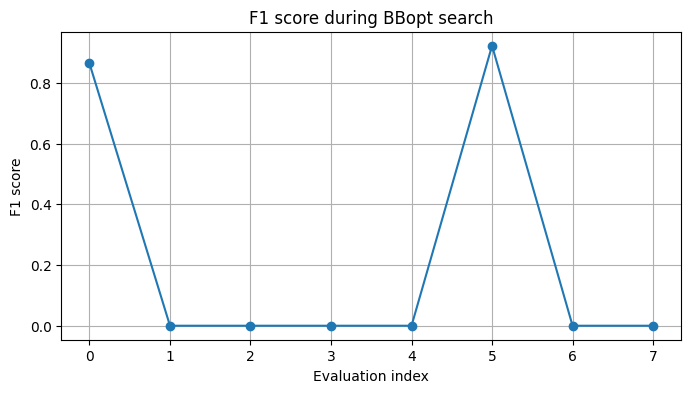

In [53]:
# BBopt探索中のF1スコア
plt.figure(figsize=(8, 4))
plt.plot(range(len(f1_hist)), f1_hist, marker="o")
plt.xlabel("Evaluation index")
plt.ylabel("F1 score")
plt.title("F1 score during BBopt search")
plt.grid(True)
plt.show()

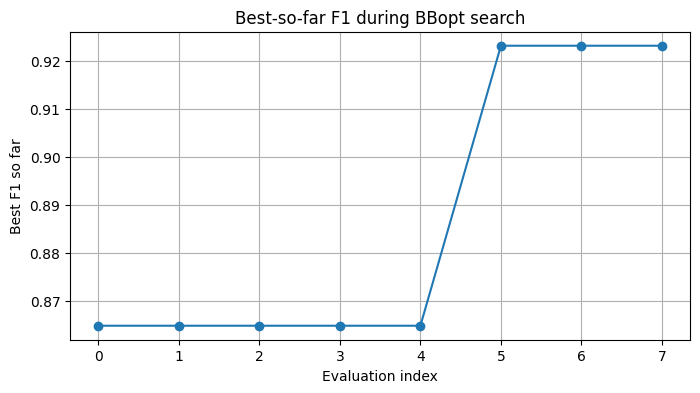

In [54]:
# その時点でのベストスコア
best_so_far_f1 = np.maximum.accumulate(f1_hist)

plt.figure(figsize=(8, 4))
plt.plot(range(len(best_so_far_f1)), best_so_far_f1, marker="o")
plt.xlabel("Evaluation index")
plt.ylabel("Best F1 so far")
plt.title("Best-so-far F1 during BBopt search")
plt.grid(True)
plt.show()

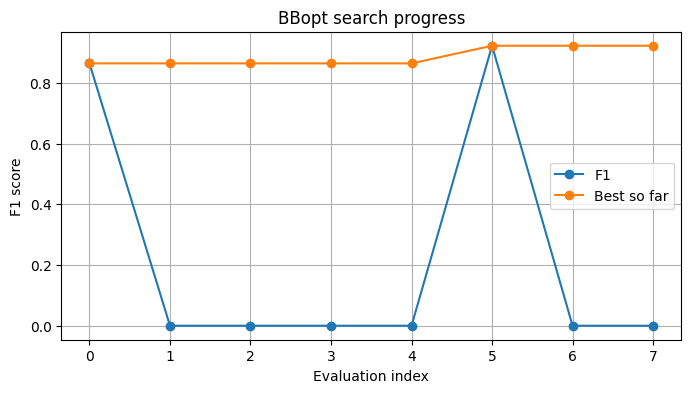

In [55]:
# ２つをまとめて表示
plt.figure(figsize=(8, 4))
plt.plot(range(len(f1_hist)), f1_hist, marker="o", label="F1")
plt.plot(range(len(best_so_far_f1)), best_so_far_f1, marker="o", label="Best so far")
plt.xlabel("Evaluation index")
plt.ylabel("F1 score")
plt.title("BBopt search progress")
plt.grid(True)
plt.legend()
plt.show()

In [56]:
# テーブル出力
history_rows = []

for i, (x_bits, obj_val, f1_val) in enumerate(zip(X_hist, y_obj_hist, f1_hist)):
    params = decode_bitvector(x_bits)
    history_rows.append({
        "step": i,
        "objective": obj_val,
        "f1": f1_val,
        "pca_dim": params["pca_dim"],
        "metric": params["metric"],
        "center_mode": params["center_mode"],
        "thr_mode": params["thr_mode"],
        "thr_value": params["thr_value"],
    })

df_history = pd.DataFrame(history_rows)
df_history.head(10)

,step,objective,f1,pca_dim,metric,center_mode,thr_mode,thr_value
0,0,-0.864865,0.864865,16,euclidean,medoid,percentile,99.429921
1,1,-0.000000,0.000000,24,cosine,medoid,fixed_margin,3.070866
2,2,-0.000000,0.000000,64,cosine,mean,fixed_margin,0.787402
3,3,-0.000000,0.000000,32,cosine,medoid,fixed_margin,4.645669
4,4,-0.000000,0.000000,64,cosine,medoid,fixed_margin,3.543307
5,5,-0.923077,0.923077,64,euclidean,medoid,zscore,3.299213
6,6,-0.000000,0.000000,32,cosine,medoid,fixed_margin,4.448819
7,7,-0.000000,0.000000,32,cosine,medoid,fixed_margin,0.511811


In [57]:
# f1の高い順
df_history_sorted = df_history.sort_values("f1", ascending=False).reset_index(drop=True)
df_history_sorted.head(10)

,step,objective,f1,pca_dim,metric,center_mode,thr_mode,thr_value
0,5,-0.923077,0.923077,64,euclidean,medoid,zscore,3.299213
1,0,-0.864865,0.864865,16,euclidean,medoid,percentile,99.429921
2,2,-0.000000,0.000000,64,cosine,mean,fixed_margin,0.787402
3,1,-0.000000,0.000000,24,cosine,medoid,fixed_margin,3.070866
4,3,-0.000000,0.000000,32,cosine,medoid,fixed_margin,4.645669
5,4,-0.000000,0.000000,64,cosine,medoid,fixed_margin,3.543307
6,6,-0.000000,0.000000,32,cosine,medoid,fixed_margin,4.448819
7,7,-0.000000,0.000000,32,cosine,medoid,fixed_margin,0.511811


### 10.9 最良設定での判定結果の可視化

ブラックボックス最適化によって得られた最良設定について、実際にどのような判定が行われたかを確認します。

まず、混同行列を用いて正常／異常の判定結果を整理します。次に、PCA 空間上で各サンプルを表示し、正常と異常がどのように分かれているかを確認します。さらに、異常と判定された画像の例を表示することで、最適化によって得られた設定がどのようなサンプルを異常として捉えているかを具体的に見ていきます。

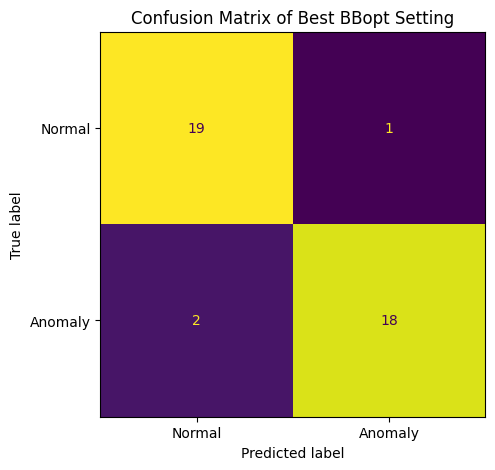

In [58]:
# 混同行列の表示
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_best = confusion_matrix(y_eval, best_result["y_pred"], labels=[0, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=cm_best, display_labels=["Normal", "Anomaly"])

fig, ax = plt.subplots(figsize=(5, 5))
disp.plot(ax=ax, colorbar=False)
plt.title("Confusion Matrix of Best BBopt Setting")
plt.show()

In [59]:
print("Confusion matrix (rows=true, cols=pred)")
print(cm_best)

tn, fp, fn, tp = cm_best.ravel()
print()
print(f"TN={tn}, FP={fp}, FN={fn}, TP={tp}")

Confusion matrix (rows=true, cols=pred)
[[19  1]
 [ 2 18]]

TN=19, FP=1, FN=2, TP=18


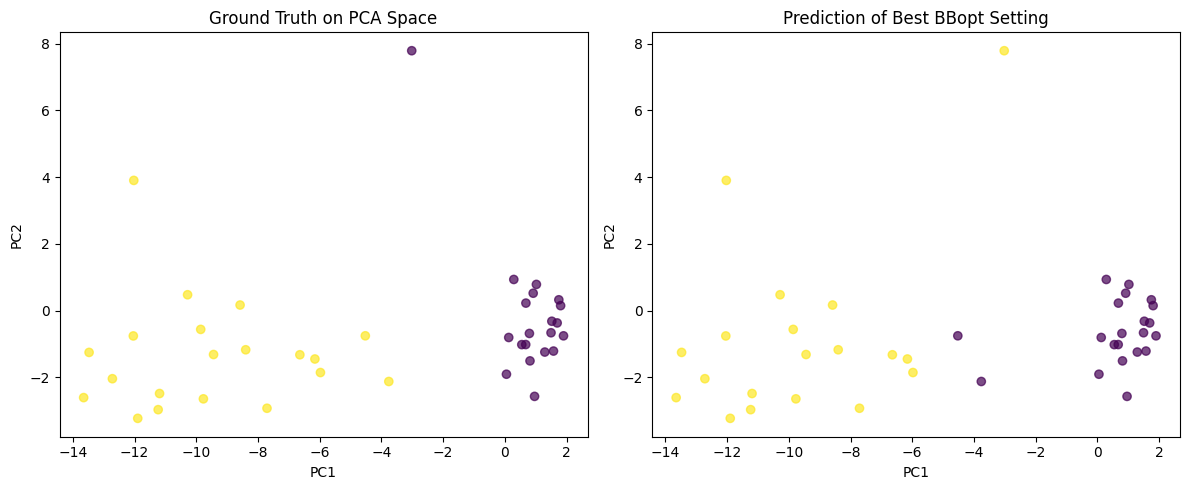

In [60]:
# 最良設定の PCA 空間
eval_features_pca = best_result["eval_features_pca"]
y_pred_best = best_result["y_pred"]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(eval_features_pca[:, 0], eval_features_pca[:, 1], c=y_eval, alpha=0.7)
axes[0].set_title("Ground Truth on PCA Space")
axes[0].set_xlabel("PC1")
axes[0].set_ylabel("PC2")

axes[1].scatter(eval_features_pca[:, 0], eval_features_pca[:, 1], c=y_pred_best, alpha=0.7)
axes[1].set_title("Prediction of Best BBopt Setting")
axes[1].set_xlabel("PC1")
axes[1].set_ylabel("PC2")

plt.tight_layout()
plt.show()

In [61]:
## 正常中心と閾値の確認
print("Best parameters")
print("---------------")
for k, v in best_params.items():
    print(f"{k}: {v}")

print()
print("threshold:", best_result["threshold"])
print("number of predicted anomalies:", int(np.sum(best_result["y_pred"] == 1)))
print("number of true anomalies     :", int(np.sum(y_eval == 1)))

Best parameters
---------------
pca_idx: 4
metric_idx: 0
center_idx: 1
thr_mode_idx: 1
thr_value_int: 79
pca_dim: 64
metric: euclidean
center_mode: medoid
thr_mode: zscore
thr_value: 3.2992125984251968

threshold: 10.510354042053223
number of predicted anomalies: 19
number of true anomalies     : 20


predicted anomaly count: 19


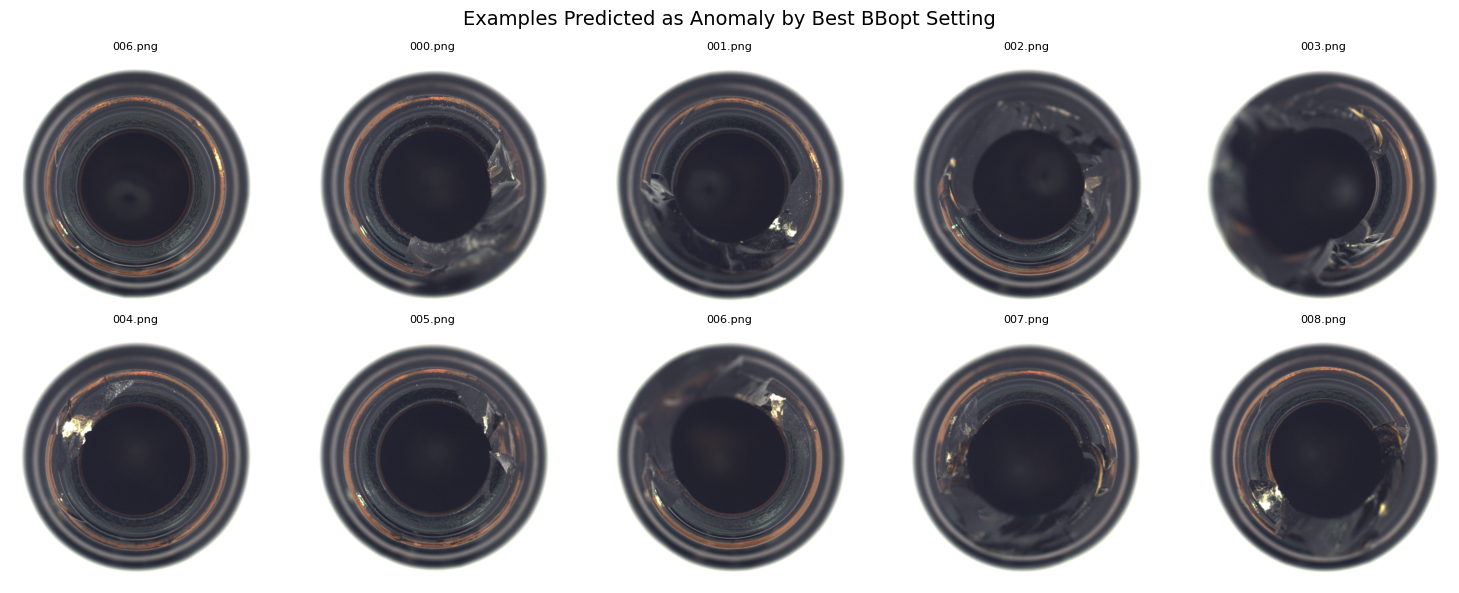

In [62]:
# 異常画像の表示
from pathlib import Path
from PIL import Image
import math

eval_image_paths = test_good + test_defective
pred_anomaly_paths = [
    path for path, pred in zip(eval_image_paths, best_result["y_pred"]) if pred == 1
]

print("predicted anomaly count:", len(pred_anomaly_paths))

n_show = min(10, len(pred_anomaly_paths))
cols = 5
rows = math.ceil(n_show / cols) if n_show > 0 else 1

plt.figure(figsize=(15, 3 * rows))

for i, path in enumerate(pred_anomaly_paths[:n_show], 1):
    img = Image.open(path)
    plt.subplot(rows, cols, i)
    plt.imshow(img)
    plt.title(Path(path).name, fontsize=8)
    plt.axis("off")

plt.suptitle("Examples Predicted as Anomaly by Best BBopt Setting", fontsize=14)
plt.tight_layout()
plt.show()

In [63]:
# 誤判定
fp_paths = [
    path for path, yt, yp in zip(eval_image_paths, y_eval, best_result["y_pred"])
    if yt == 0 and yp == 1
]

fn_paths = [
    path for path, yt, yp in zip(eval_image_paths, y_eval, best_result["y_pred"])
    if yt == 1 and yp == 0
]

print("false positives:", len(fp_paths))
print("false negatives:", len(fn_paths))

false positives: 1
false negatives: 2


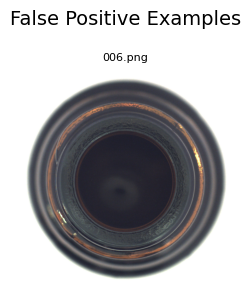

In [64]:
# 偽陽性の例
n_show = min(5, len(fp_paths))

if n_show > 0:
    plt.figure(figsize=(15, 3))
    for i, path in enumerate(fp_paths[:n_show], 1):
        img = Image.open(path)
        plt.subplot(1, n_show, i)
        plt.imshow(img)
        plt.title(Path(path).name, fontsize=8)
        plt.axis("off")
    plt.suptitle("False Positive Examples", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print("False Positive はありません。")

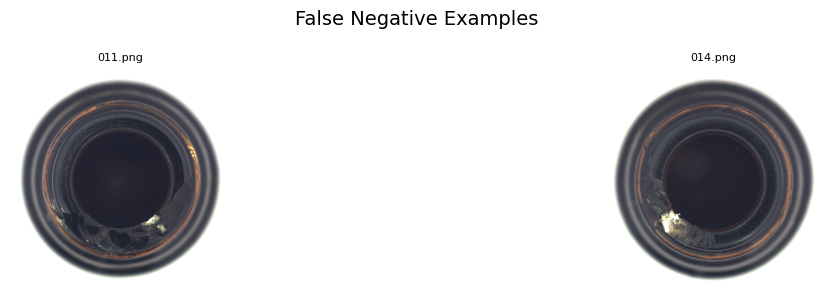

In [65]:
# 偽陰性の例
n_show = min(5, len(fn_paths))

if n_show > 0:
    plt.figure(figsize=(15, 3))
    for i, path in enumerate(fn_paths[:n_show], 1):
        img = Image.open(path)
        plt.subplot(1, n_show, i)
        plt.imshow(img)
        plt.title(Path(path).name, fontsize=8)
        plt.axis("off")
    plt.suptitle("False Negative Examples", fontsize=14)
    plt.tight_layout()
    plt.show()
else:
    print("False Negative はありません。")

### 10.10 まとめ

本章では、`amplify-bbopt-ext` を用いて、距離ベース異常検知器の設定をブラックボックス最適化により探索しました。

まず、異常検知器の設定をビット列として表現し、各候補に対して異常検知を実行して F1 スコアを評価しました。次に、`latest_filter.run(...)` により探索を行い、最良の設定を得ました。さらに、探索履歴を可視化することで、評価値がどのように改善したかを確認しました。

最後に、得られた最良設定について混同行列や PCA 空間上の分布、異常と判定された画像例を確認し、最適化によってどのような判定性能が得られたかを把握しました。

このように、ブラックボックス最適化を用いることで、異常検知器の複数の設定を自動的に探索し、性能の高い組合せを見つけられることが確認できました。